# Comparison with the digitised ESHM20 correlations

Compares the raw (before the positive-definite adjustment) total-residual SA-SA correlations
of the CG26 model for reverse faulting in the active shallow crust with correlations digitised
from plots of the ESHM20 project. The model is read from the csv nb `002-im_correlations`
writes (`data_processed/02_im_correlation_model/reverse/correlations/asc_reverse_rho_total.csv`),
not recomputed.

In [1]:
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from phd_project.config.config import load_config
from phd_project.plotting.plotting import custom_log_formatter
from phd_project.scripts.WP1_ground_motion_set.correlation import read_correlation_csv

cfg = load_config()
PROCESSED_DATA = cfg["proc_data"]["corr_model"]

In [2]:
# The raw reverse-faulting ASC total-residual correlations written by nb 002, held in the same
# nested dict layout nb 002 uses (rhos[fault type][region][residual type]) so the plotting code
# below reads them as it does there
rhos = {"reverse": {"asc": {"rho_total": read_correlation_csv(
    PROCESSED_DATA / "reverse" / "correlations" / "asc_reverse_rho_total.csv")}}}

## Compare with Data from the ESHM20 Project

The data was digitized from plots provided by Graeme Weatherill from the Deutsche Geoforschungszentrum, Potsdam

In [3]:
folder = cfg["raw_data"]["rho_models"] / "ESHM20"
periods = [0.05, 0.20, 1.00, 4.00]

eshm20_data = []
for t in periods:
    t_pt = f"{t:.2f}".replace(".", "pt")
    eshm20_data.append(np.loadtxt(folder / f"rho_T_{t_pt}.csv", delimiter=","))

Text(0, 0.5, '$\\rho_{SA_{i}SA_{j}}$ [-]')

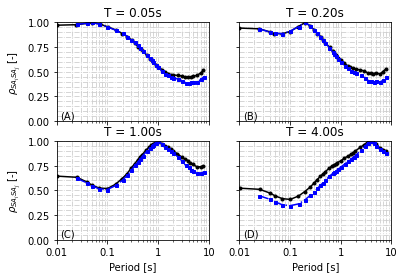

In [4]:
idx = pd.IndexSlice
rho_model = rhos["reverse"]["asc"]["rho_total"]


fig, axs = plt.subplots(2, 2, sharex=True, sharey=True)
axs = axs.flatten()

for ii, (t, eshm20) in enumerate(zip(periods, eshm20_data)):
    axs[ii].semilogx(eshm20[:,0], eshm20[:,1], color="k", marker="o", ls="-",
                     ms=3.0, label="ESHM20")
    axs[ii].semilogx(rho_model.loc[idx["rotD50", "SA", t], idx["rotD50", "SA", :]].index.get_level_values(2),
                     rho_model.loc[idx["rotD50", "SA", t], idx["rotD50", "SA", :]],
                     color="b", marker="s", ls="-.",ms=3.0, label="ESHM20")

for ii, (ax, t) in enumerate(zip(axs, periods)):
    ax.grid(True, which="both", ls="-.", color="0.8")
    ax.minorticks_on()
    ax.tick_params(axis='y', which='minor', left=False)
    ax.set_xlim(0.01, 10)
    ax.set_ylim(0, 1.0)
    formatter = ticker.FuncFormatter(custom_log_formatter)
    ax.xaxis.set_major_formatter(formatter)
    ax.text(0.012, 0.03, f"({string.ascii_uppercase[ii]})")
    ax.set_title(f"T = {t:.2f}s")

axs[2].set_xlabel("Period [s]")
axs[3].set_xlabel("Period [s]")
axs[0].set_ylabel("$\\rho_{SA_{i}SA_{j}}$ [-]")
axs[2].set_ylabel("$\\rho_{SA_{i}SA_{j}}$ [-]")